In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.15.0+cpu
CUDA available: False


In [8]:
!pip install torch torchvision matplotlib numpy


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\mpsru\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [2]:
import torch
import torchvision
import torchvision.transforms as transforms
import numpy as np
import random
import matplotlib.pyplot as plt

In [3]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Seed set successfully")


Seed set successfully


In [8]:
transform = transforms.ToTensor()

train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))

100.0%


Training images: 50000
Test images: 10000


In [9]:
from torch.utils.data import random_split

train_size = 45000
val_size = 5000

train_dataset, val_dataset = random_split(
    train_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)

print("Train images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

Train images: 45000
Validation images: 5000
Test images: 10000


In [10]:
from torch.utils.data import DataLoader

batch_size = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("DataLoaders created successfully")

DataLoaders created successfully


In [11]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

Images shape: torch.Size([128, 3, 32, 32])
Labels shape: torch.Size([128])


In [12]:
import torch.nn as nn

class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(3072, 512)
        self.relu1 = nn.ReLU()

        self.fc2 = nn.Linear(512, 256)
        self.relu2 = nn.ReLU()

        self.fc3 = nn.Linear(256, 10)

    def forward(self, x):
        x = self.flatten(x)

        x = self.fc1(x)
        x = self.relu1(x)

        x = self.fc2(x)
        x = self.relu2(x)

        x = self.fc3(x)

        return x


model = MLP()

print(model)

MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=3072, out_features=512, bias=True)
  (relu1): ReLU()
  (fc2): Linear(in_features=512, out_features=256, bias=True)
  (relu2): ReLU()
  (fc3): Linear(in_features=256, out_features=10, bias=True)
)


In [13]:
images, labels = next(iter(train_loader))

outputs = model(images)

print("Output shape:", outputs.shape)

Output shape: torch.Size([128, 10])


In [14]:
total_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Trainable Parameters:", total_params)

Trainable Parameters: 1707274


In [15]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss and Optimizer ready")

Loss and Optimizer ready


In [17]:
def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:

        outputs = model(images)

        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(loader)
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc


In [18]:
def evaluate(model, loader, criterion):

    model.eval()

    running_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(loader)
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc


In [19]:
epochs = 20

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

for epoch in range(epochs):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    val_loss, val_acc = evaluate(
        model,
        val_loader,
        criterion
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

Epoch 1/20 | Train Loss: 1.8650 | Train Acc: 32.20% | Val Loss: 1.7441 | Val Acc: 36.28%
Epoch 2/20 | Train Loss: 1.6751 | Train Acc: 39.80% | Val Loss: 1.6352 | Val Acc: 41.68%
Epoch 3/20 | Train Loss: 1.5930 | Train Acc: 42.92% | Val Loss: 1.5907 | Val Acc: 43.80%
Epoch 4/20 | Train Loss: 1.5185 | Train Acc: 45.62% | Val Loss: 1.5530 | Val Acc: 45.38%
Epoch 5/20 | Train Loss: 1.4785 | Train Acc: 47.16% | Val Loss: 1.4866 | Val Acc: 47.24%
Epoch 6/20 | Train Loss: 1.4495 | Train Acc: 48.30% | Val Loss: 1.4934 | Val Acc: 47.54%
Epoch 7/20 | Train Loss: 1.4149 | Train Acc: 49.51% | Val Loss: 1.4956 | Val Acc: 47.02%
Epoch 8/20 | Train Loss: 1.3864 | Train Acc: 50.41% | Val Loss: 1.4542 | Val Acc: 48.50%
Epoch 9/20 | Train Loss: 1.3599 | Train Acc: 51.59% | Val Loss: 1.4714 | Val Acc: 47.20%
Epoch 10/20 | Train Loss: 1.3288 | Train Acc: 52.47% | Val Loss: 1.4392 | Val Acc: 48.42%
Epoch 11/20 | Train Loss: 1.3130 | Train Acc: 53.36% | Val Loss: 1.4129 | Val Acc: 49.80%
Epoch 12/20 | Train

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

In [21]:
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Trainable Parameters:", total_params)

Trainable Parameters: 1707274


In [25]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total

print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Accuracy: 51.71%


In [23]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(device)

cpu


In [24]:
model = model.to(device)

In [26]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total

print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Accuracy: 51.71%


In [27]:
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Trainable Parameters:", total_params)

Trainable Parameters: 1707274


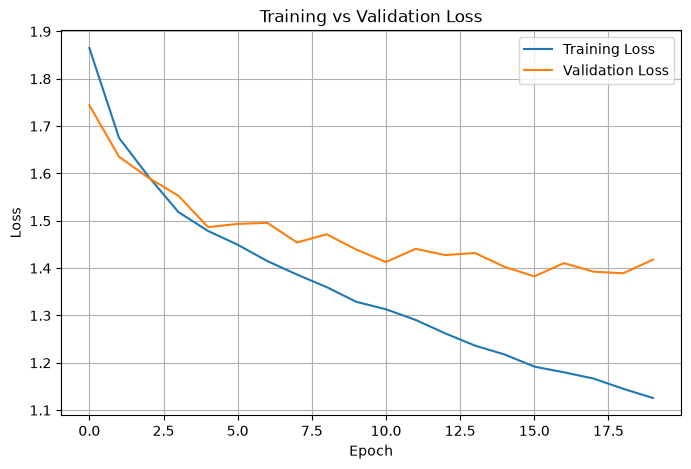

In [28]:
plt.figure(figsize=(8,5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

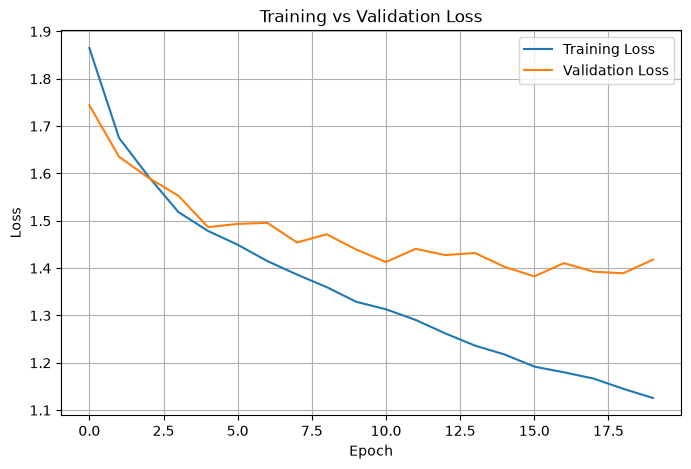

In [29]:
plt.figure(figsize=(8,5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.savefig("exercise1_loss_plot.png")

plt.show()